<a href="https://colab.research.google.com/github/nadjib-ken/T7Vr2-B5/blob/main/T7Vr2-B5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Step 0: Problem Definition & Hypotheses (Pair T7Vr2-B5)


1. Problem Definition
We are using a Decision Tree model to predict the severity of road accidents in Addis Ababa (Slight, Serious, or Fatal) based only on the pre-crash circumstances (weather, road, driver, and vehicle info), excluding post-crash casualty variables to prevent data leakage. We will fix random_state = 42 everywhere so our results are reproducible.

2. Hypotheses (Our Predictions Before Testing)
- Hypothesis 1 (Scaling): Scaling the data (StandardScaler) will not change our Decision Tree's score, because Decision Trees use simple if/else rules instead of distances.
- Hypothesis 2 (Overfitting): Making the tree too deep (max_depth = None) will hurt test performance because the tree will memorize noise instead of learning general rules.
- Hypothesis 3 (Rare Fatal Crashes): Because fatal accidents are rare compared to slight injuries, the model will miss most of them unless we use class_weight='balanced' or resampling.

# Step 1: Exploratory Data Analysis

In [5]:
import random
import numpy as np
import pandas as pd

# Step 0: Reproducibility Seed
RANDOM_STATE = 42
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)

# Step 1: Load Data & EDA
url = "https://raw.githubusercontent.com/nadjib-ken/T7Vr2-B5/main/raw_Addis_Ababa_city_RTA.csv"
df = pd.read_csv(url)

print("1. SHAPE:", df.shape)
print("\n2. DATA TYPES:\n", df.dtypes)

print("\n3. MISSING VALUES (NaN):")
missing = df.isnull().sum()
print(missing[missing > 0])

print("\n4. UNKNOWN / NA TEXT VALUES:")
for col in df.columns:
    unk = df[col].astype(str).str.strip().str.lower().isin(["unknown", "na"]).sum()
    if unk > 0:
        print(f"  {col}: {unk}")

print("\n5. DUPLICATE ROWS:", df.duplicated().sum())

target = "Accident_severity"
print("\n6. TARGET DISTRIBUTION (CLASS BALANCE):")
print(pd.DataFrame({
    "Count": df[target].value_counts(),
    "Percent": (df[target].value_counts(normalize=True) * 100).round(2)
}))

print("\n7. FEATURE INSIGHTS (Light_conditions vs Severity %):")
print((pd.crosstab(df["Light_conditions"], df[target], normalize="index") * 100).round(2))

print("\n8. NUMBER OF VEHICLES INVOLVED:")
print(df["Number_of_vehicles_involved"].value_counts().sort_index())

leakage_cols = [
    "Number_of_casualties", "Casualty_class", "Casualty_gender",
    "Age_band_of_casualty", "Work_of_casuality", "Fitness_of_casuality"
]
print("\n9. LEAKAGE COLUMNS TO DROP IN STEP 2:", leakage_cols)

1. SHAPE: (13063, 31)

2. DATA TYPES:
 Time                           object
Day_of_week                    object
Age_band_of_driver             object
Drivers_gender                 object
Educational_level              object
Vehicle_driver_relation        object
Driving_experience             object
Type_of_vehicle                object
Owner_of_vehicle               object
Service_year_of_vehicle        object
Defect_of_vehicle              object
Area_accident_occured          object
Lanes_or_Medians               object
Road_allignment                object
Types_of_Junction              object
Road_surface_type              object
Road_surface_conditions        object
Light_conditions               object
Weather_conditions             object
Type_of_collision              object
Number_of_vehicles_involved     int64
Number_of_casualties            int64
Vehicle_movement               object
Casualty_class                 object
Casualty_gender                object
Age_band_of

# Step 2: Cleaning & Encoding

In [6]:
# -------------------------------------------------------------------------
# 1. Define Noise Placeholders
# -------------------------------------------------------------------------
missing_placeholders = [
    "", " ", "na", "n/a", "nan", "null", "none", "nil", "n/d", "tbd", "tbc",
    "unk", "unknown", "missing", "blank", "-", "--", "?", ".", "*", "#n/a", "#value!"
]

# -------------------------------------------------------------------------
# 2. Exact Duplicate Removal
# -------------------------------------------------------------------------
initial_rows = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f"Duplicates removed: {initial_rows - len(df)} rows dropped (Total remaining: {len(df)})")

# -------------------------------------------------------------------------
# 3. Target & Data Leakage Isolation (G2 Classification)
# -------------------------------------------------------------------------
target_col = "Accident_severity"
leakage_cols = [
    "Number_of_casualties",
    "Casualty_class",
    "Casualty_gender",
    "Age_band_of_casualty",
    "Work_of_casuality",
    "Fitness_of_casuality"
]
exclude_of_category_grouping = [
    "Time",
    "Day_of_week"
]

# Separate Target (y) and Feature Matrix (X)
y = df[target_col]
X = df.drop(columns=[target_col] + leakage_cols)

# -------------------------------------------------------------------------
# 4. Missing Value & "Unknown" Standardization
# -------------------------------------------------------------------------
string_cols = X.select_dtypes(include=['object', 'string']).columns
num_cols = X.select_dtypes(include=['int64', 'float64']).columns

for col in string_cols:
    X[col] = X[col].astype(str).str.strip().str.lower()
    X[col] = X[col].replace(missing_placeholders, "unknown")
    X[col] = X[col].fillna("unknown")

for col in num_cols:
    X[col] = X[col].replace(missing_placeholders, np.nan)

# -------------------------------------------------------------------------
# 5. Rare Category Consolidation (< 0.1% Cutoff per Column)
# -------------------------------------------------------------------------
threshold = 0.001 * len(X)

for col in string_cols.difference(exclude_of_category_grouping):
    counts = X[col].value_counts()
    rare_categories = counts[(counts < threshold) & (counts.index != 'unknown')].index
    if len(rare_categories) > 0:
        X[col] = X[col].replace(rare_categories, "other")

# -------------------------------------------------------------------------
# 6. Recombine & Export Single Deliverable
# -------------------------------------------------------------------------
df_clean = X.copy()
df_clean[target_col] = y

df_clean.to_csv("T7Vr2-B5_dataset_clean.csv", index=False)
print(f"Cleaning completed successfully! Shape: {df_clean.shape} -> Saved to 'T7Vr2-B5_dataset_clean.csv'.")

Duplicates removed: 0 rows dropped (Total remaining: 13063)
Cleaning completed successfully! Shape: (13063, 25) -> Saved to 'T7Vr2-B5_dataset_clean.csv'.


# Step 3: Reference Splits

In [7]:
from sklearn.model_selection import train_test_split, RepeatedStratifiedKFold

df_clean = pd.read_csv("T7Vr2-B5_dataset_clean.csv")

target_col = "Accident_severity"
X = df_clean.drop(columns=[target_col])
y = df_clean[target_col]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE
)

df_clean['split_ref'] = 'train'
df_clean.loc[X_test.index, 'split_ref'] = 'test'

df_clean.to_csv("T7Vr2-B5_dataset_clean.csv", index=False)
print("Updated 'T7Vr2-B5_dataset_clean.csv' with 'split_ref' column successfully!\n")
print(f"Total dataset: {len(df_clean)} rows")
print(f"Train set:     {len(X_train)} rows ({len(X_train)/len(df_clean):.1%})")
print(f"Test set:      {len(X_test)} rows ({len(X_test)/len(df_clean):.1%})")

cv_reference = RepeatedStratifiedKFold(
    n_splits=5,
    n_repeats=3,
    random_state=42
)

print("\nRepeatedStratifiedKFold (5 folds x 3 repeats) ready for model training!")

Updated 'T7Vr2-B5_dataset_clean.csv' with 'split_ref' column successfully!

Total dataset: 13063 rows
Train set:     10450 rows (80.0%)
Test set:      2613 rows (20.0%)

RepeatedStratifiedKFold (5 folds x 3 repeats) ready for model training!


# Step 4: Baseline Model

In [9]:
import time
import numpy as np
import pandas as pd
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate
from sklearn.metrics import make_scorer, f1_score, recall_score, balanced_accuracy_score

# 1. Load clean data & keep only the 80% Reference Train set
df_clean = pd.read_csv("T7Vr2-B5_dataset_clean.csv")
train_df = df_clean[df_clean["split_ref"] == "train"].copy()

X_train = train_df.drop(columns=["Accident_severity", "split_ref"])
y_train = train_df["Accident_severity"]

# 2. Define Reference CV & clean scorers (no NaNs)
cv_reference = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=42)

def fatal_recall_fn(y_true, y_pred):
    return recall_score(y_true, y_pred, labels=["Fatal injury"], average="macro", zero_division=0)

def macro_f1_fn(y_true, y_pred):
    return f1_score(y_true, y_pred, average="macro", zero_division=0)

scoring = {
    "macro_f1": make_scorer(macro_f1_fn),
    "fatal_recall": make_scorer(fatal_recall_fn),
    "balanced_acc": make_scorer(balanced_accuracy_score),
    "accuracy": "accuracy"
}

# 3. Run Baseline (DummyClassifier: most_frequent)
baseline = DummyClassifier(strategy="most_frequent", random_state=42)

t0 = time.perf_counter()
cv_res = cross_validate(baseline, X_train, y_train, cv=cv_reference, scoring=scoring)
elapsed = time.perf_counter() - t0

# 4. Print Results
summary = pd.DataFrame({
    "Metric": ["Macro-F1", "Fatal Recall", "Balanced Accuracy", "Raw Accuracy"],
    "Mean": [
        cv_res["test_macro_f1"].mean(),
        cv_res["test_fatal_recall"].mean(),
        cv_res["test_balanced_acc"].mean(),
        cv_res["test_accuracy"].mean()
    ],
    "Std": [
        cv_res["test_macro_f1"].std(),
        cv_res["test_fatal_recall"].std(),
        cv_res["test_balanced_acc"].std(),
        cv_res["test_accuracy"].std()
    ]
})

print(summary.to_string(index=False, float_format=lambda x: f"{x:.4f}"))
print(f"\nTotal CV Time: {elapsed:.4f}s")

           Metric   Mean    Std
         Macro-F1 0.3013 0.0000
     Fatal Recall 0.0000 0.0000
Balanced Accuracy 0.3333 0.0000
     Raw Accuracy 0.8249 0.0000

Total CV Time: 0.3485s


# Step 5: Decision Tree Hyperparameter Tuning

=== STEP 5: GRID SEARCH RESULTS (20 Configs | Time: 81.04s) ===
Best Params (by Macro-F1): {'clf__max_depth': None, 'clf__min_samples_leaf': 1}

max_depth  min_samples_leaf  mean_test_macro_f1  std_test_macro_f1  mean_test_fatal_recall  mean_test_balanced_acc  mean_train_macro_f1
     None                 1              0.4818             0.0243                  0.3732                  0.4982               1.0000
     None                 2              0.4572             0.0181                  0.3546                  0.4856               0.8917
        3                 2              0.4557             0.0294                  0.2850                  0.4663               0.4698
        3                 1              0.4556             0.0293                  0.2850                  0.4662               0.4700
        3                 5              0.4546             0.0287                  0.2823                  0.4652               0.4696
        3                10            

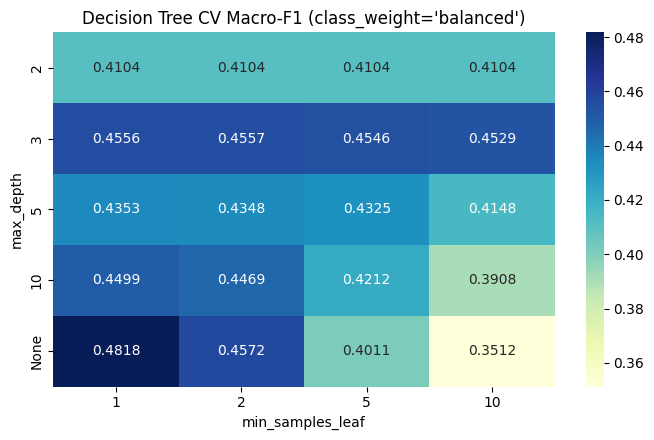

In [10]:
import time
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV

# 1. Separate categorical vs numeric columns (One-Hot fitted inside CV folds)
cat_cols = X_train.select_dtypes(include=["object", "string"]).columns.tolist()
num_cols = X_train.select_dtypes(include=["int64", "float64"]).columns.tolist()

preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
        ("num", "passthrough", num_cols)
    ]
)

pipe = Pipeline([
    ("prep", preprocessor),
    ("clf", DecisionTreeClassifier(
        criterion="gini",
        class_weight="balanced",
        random_state=42
    ))
])

# 2. Exact Hyperparameter Grid (5 x 4 = 20 configurations)
param_grid = {
    "clf__max_depth": [2, 3, 5, 10, None],
    "clf__min_samples_leaf": [1, 2, 5, 10]
}

t0 = time.perf_counter()
grid = GridSearchCV(
    estimator=pipe,
    param_grid=param_grid,
    cv=cv_reference,
    scoring=scoring,
    refit="macro_f1",
    n_jobs=-1,
    return_train_score=True
)
grid.fit(X_train, y_train)
elapsed = time.perf_counter() - t0

# 3. Extract & Display Results Table
res = pd.DataFrame(grid.cv_results_)
res["max_depth"] = res["param_clf__max_depth"].fillna("None").astype(str)
res["min_samples_leaf"] = res["param_clf__min_samples_leaf"].astype(int)

summary_cols = [
    "max_depth", "min_samples_leaf",
    "mean_test_macro_f1", "std_test_macro_f1",
    "mean_test_fatal_recall", "mean_test_balanced_acc",
    "mean_train_macro_f1"
]
print(f"=== STEP 5: GRID SEARCH RESULTS (20 Configs | Time: {elapsed:.2f}s) ===")
print(f"Best Params (by Macro-F1): {grid.best_params_}\n")
print(res[summary_cols].sort_values(by="mean_test_macro_f1", ascending=False).to_string(index=False, float_format=lambda x: f"{x:.4f}"))

# 4. Plot Validation Heatmap (Macro-F1 across the 20 configs)
pivot_f1 = res.pivot(index="max_depth", columns="min_samples_leaf", values="mean_test_macro_f1")
pivot_f1 = pivot_f1.reindex(["2", "3", "5", "10", "None"])

plt.figure(figsize=(7, 4.5))
sns.heatmap(pivot_f1, annot=True, fmt=".4f", cmap="YlGnBu")
plt.title("Decision Tree CV Macro-F1 (class_weight='balanced')")
plt.ylabel("max_depth")
plt.xlabel("min_samples_leaf")
plt.tight_layout()
plt.show()